# Retail Demand Intelligence — EDA & 4-Model Comparison

Runs cleanly on `data/m5_subset.csv` (60 balanced SKUs from Store `CA_1`, 365 days) and `models/metrics.json` to produce report-ready EDA and model evaluation figures.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 120
repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(repo_root / "data" / "m5_subset.csv")
df["date"] = pd.to_datetime(df["date"])
df["revenue"] = df["sales"] * df["sell_price"]

print(f"Rows: {len(df):,} | SKUs: {df['item_id'].nunique()} | Range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Zero-sales days overall: {100.0 * (df['sales'] == 0).mean():.2f}%")
df.head()

Rows: 21,060 | SKUs: 60 | Range: 2015-05-10 to 2016-04-24
Zero-sales days overall: 50.97%


,item_id,dept_id,cat_id,store_id,date,sales,lag_7,lag_14,rolling_mean_7,rolling_mean_28,day_of_week,month,sell_price,snap_CA,revenue
0,FOODS_1_001,FOODS_1,FOODS,CA_1,2015-05-10,0,0.0,0.0,0.5714,0.5000,6,5,2.24,1,0.00
1,FOODS_1_001,FOODS_1,FOODS,CA_1,2015-05-11,0,2.0,1.0,0.7143,0.6667,0,5,2.24,0,0.00
2,FOODS_1_001,FOODS_1,FOODS,CA_1,2015-05-12,1,0.0,0.0,0.7143,0.6000,1,5,2.24,0,2.24
3,FOODS_1_001,FOODS_1,FOODS,CA_1,2015-05-13,0,1.0,0.0,0.8571,0.6364,2,5,2.24,0,0.00
4,FOODS_1_001,FOODS_1,FOODS,CA_1,2015-05-14,0,0.0,0.0,0.8571,0.5833,3,5,2.24,0,0.00


## 1. Category Volume, Revenue & Zero-Sales Intermittency

,skus,total_units,total_revenue,zero_sales_pct,avg_price
cat_id,,,,,
FOODS,20,13772,29338.44,49.76,2.93
HOBBIES,20,13105,18416.35,56.41,3.91
HOUSEHOLD,20,8331,42105.00,46.75,6.67


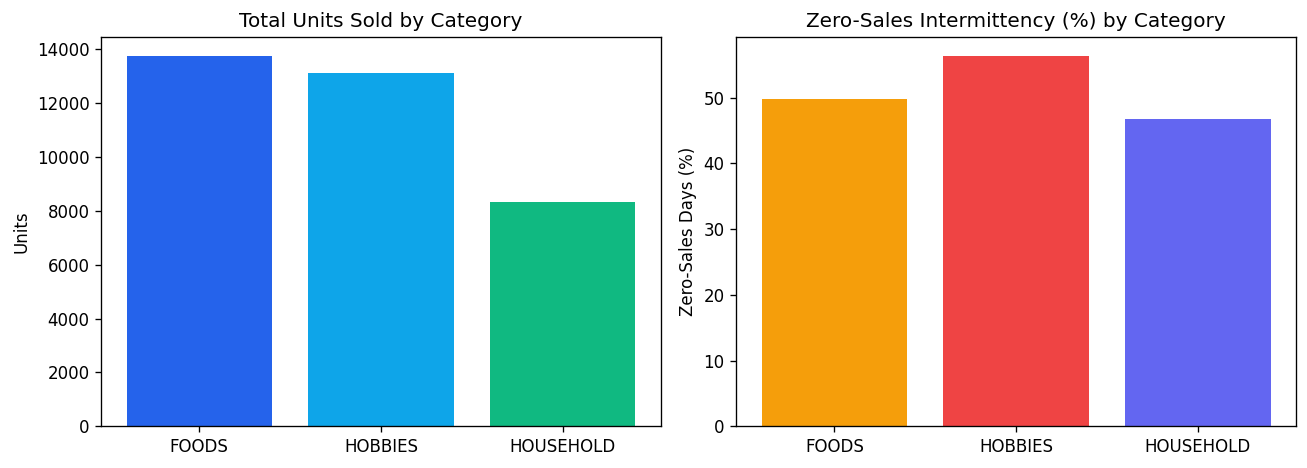

In [2]:
cat_tbl = df.groupby("cat_id").agg(
    skus=("item_id", "nunique"),
    total_units=("sales", "sum"),
    total_revenue=("revenue", "sum"),
    zero_sales_pct=("sales", lambda s: round(100.0 * (s == 0).mean(), 2)),
    avg_price=("sell_price", "mean"),
).round(2)
display(cat_tbl)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(cat_tbl.index, cat_tbl["total_units"], color=["#2563eb", "#0ea5e9", "#10b981"])
axes[0].set_title("Total Units Sold by Category")
axes[0].set_ylabel("Units")

axes[1].bar(cat_tbl.index, cat_tbl["zero_sales_pct"], color=["#f59e0b", "#ef4444", "#6366f1"])
axes[1].set_title("Zero-Sales Intermittency (%) by Category")
axes[1].set_ylabel("Zero-Sales Days (%)")
plt.tight_layout()
plt.show()

## 2. Weekday Seasonality & SNAP Lift (`snap_CA`)

,Non-SNAP,SNAP Day,Lift (%)
cat_id,,,
FOODS,1.994,1.893,-5.06
HOBBIES,1.832,1.942,6.03
HOUSEHOLD,1.192,1.175,-1.47


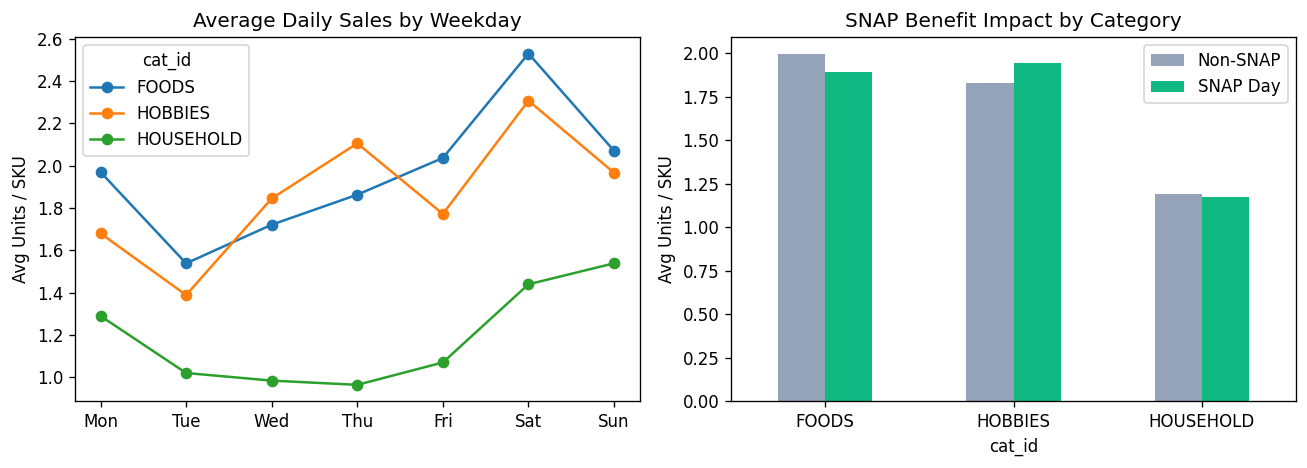

In [3]:
wd_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd_df = df.groupby(["day_of_week", "cat_id"])["sales"].mean().unstack("cat_id")
wd_df.index = [wd_names[i] for i in wd_df.index]

snap_df = df.groupby(["cat_id", "snap_CA"])["sales"].mean().unstack("snap_CA")
snap_df.columns = ["Non-SNAP", "SNAP Day"]
snap_df["Lift (%)"] = (100.0 * (snap_df["SNAP Day"] - snap_df["Non-SNAP"]) / snap_df["Non-SNAP"]).round(2)
display(snap_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
wd_df.plot(marker="o", ax=axes[0])
axes[0].set_title("Average Daily Sales by Weekday")
axes[0].set_ylabel("Avg Units / SKU")

snap_df[["Non-SNAP", "SNAP Day"]].plot(kind="bar", ax=axes[1], color=["#94a3b8", "#10b981"])
axes[1].set_title("SNAP Benefit Impact by Category")
axes[1].set_ylabel("Avg Units / SKU")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 3. 4-Model Evaluation Comparison (28-Day Chronological Test Set)

,model,mae,rmse,wmape
0,7-Day Moving Average,1.3489,2.8430,0.8523
1,Linear Regression,1.3014,2.7015,0.8222
2,Random Forest,1.3068,2.7278,0.8257
3,LightGBM,1.3013,2.7431,0.8222


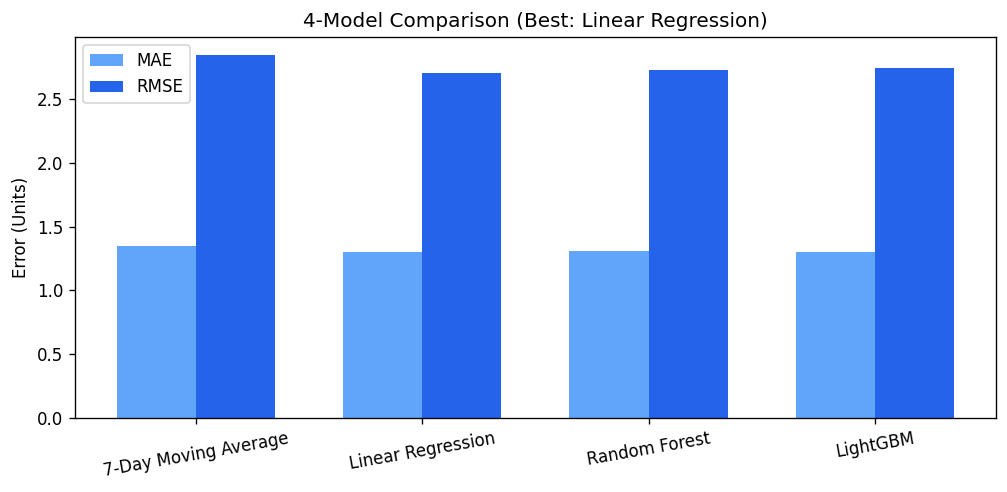

In [4]:
with open(repo_root / "models" / "metrics.json", "r", encoding="utf-8") as fh:
    metrics = json.load(fh)

comp_df = pd.DataFrame(metrics["model_comparison"])
display(comp_df)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(comp_df))
w = 0.35
ax.bar(x - w/2, comp_df["mae"], width=w, label="MAE", color="#60a5fa")
ax.bar(x + w/2, comp_df["rmse"], width=w, label="RMSE", color="#2563eb")
ax.set_xticks(x)
ax.set_xticklabels(comp_df["model"], rotation=10)
ax.set_ylabel("Error (Units)")
ax.set_title(f"4-Model Comparison (Best: {metrics['best_model']})")
ax.legend()
plt.tight_layout()
plt.show()